# 02 · Manifold — Dong 2020 Neuroblastoma

Fit the cell-state trajectory. The topology is chosen from the data: a PPT **tree** only if a
bifurcation is stable across node counts, otherwise a principal **curve** (non-branching). Root
from the signatures' **developmental order** (Gast/pSom early, Crest late — never at a
proliferation state), infer pseudotime, and render the fitted curve **with its edges drawn** so a
fold cannot hide.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb   = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Dong2020_Neuroendocrine | category: Neuroendocrine


### Load processed manifold; measure elongation
The UMAP aspect ratio (major/minor singular value) indicates whether the manifold is an
elongated strip (curve-shaped) or a compact blob.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,s,_ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

malignant manifold: 47384 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.89


### Topology control — do PPT forks scale with node count?
Fit a PPT **tree** at increasing node counts. A genuine bifurcation gives a *stable* fork; if the
fork count simply grows with the node budget, the "branches" are over-fitting a continuum and the
manifold is non-branching (fit a curve instead).

In [4]:
for N in [15, 20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        tmp = adata.copy()
        scf.tl.tree(tmp, Nodes=N, use_rep='X_umap', method='ppt',
                    ppt_sigma=1, ppt_lambda=1, seed=SEED, plot=False)
    Bt = np.asarray(tmp.uns['graph']['B'])
    print(f'PPT tree Nodes={N}: {int(((Bt>0).sum(0)==1).sum())} tips, {int(((Bt>0).sum(0)>=3).sum())} forks')
del tmp
print('-> forks scale with node count: no stable bifurcation -> NON-BRANCHING (fit a curve).')

PPT tree Nodes=15: 5 tips, 3 forks
PPT tree Nodes=20: 6 tips, 4 forks
PPT tree Nodes=30: 7 tips, 5 forks
-> forks scale with node count: no stable bifurcation -> NON-BRANCHING (fit a curve).


### Fit principal curve + fold diagnostic
Fit a principal `curve` (ElPiGraph) across node counts and, for each, compute a **fold
self-approach ratio**: the minimum Euclidean distance between graph nodes that are ≥3 edges apart,
over the median edge length. A ratio >1 means non-adjacent parts of the curve never approach in
the embedding — i.e. it is **fold-free** (the Kürten/Chen failure mode explicitly checked).

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
for N in [15, 20, 30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=N, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={N}: {tips} tips, {forks} forks | fold self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'CHOSEN curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve N=15: 2 tips, 0 forks | fold self-approach 2.99
curve N=20: 2 tips, 0 forks | fold self-approach 2.96
curve N=30: 2 tips, 0 forks | fold self-approach 2.88
CHOSEN curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.96 (>1 = fold-free)


### Derive root from developmental order; infer pseudotime
The modules encode a developmental clock: **Gast/pSom early, Crest late**. Root at the curve tip
maximising `Gast_sm + pSom_sm − Crest_sm` (the Gast/pSom-high, Crest-low developmental origin),
never at the Crest tip or a proliferation state. Then infer pseudotime and report the module
gradients along it, plus the cell-cycle caveat.

In [6]:
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho, smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, adata.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
rho_c,_ = spearmanr(t, np.maximum(g1s,g2m))
print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} '
      '(the curve tracks the proliferation gradient; Gast marks the non-cycling origin, declining along pt)')

tip 0: Gast=+0.1258 pSom=+0.2304 Crest=+0.0005
tip 2: Gast=+0.0513 pSom=+0.2269 Crest=-0.0099
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.629 p=0.0e+00
  pSom_sm: rho=-0.050 p=1.3e-27
  Crest_sm: rho=-0.033 p=1.0e-12
caveat: pseudotime vs cycling score rho = +0.80 (the curve tracks the proliferation gradient; Gast marks the non-cycling origin, declining along pt)


### Milestones + house orientation
Rename the two curve tips to their developmental identity and reuse the house left→right layout
from step 01 (do **not** re-embed a linear compartment — the Kürten fold lesson).

In [7]:
mil = {str(root): 'Origin', str(int([tp for tp in tps if tp!=root][0])): 'Terminus'}
try:
    scf.tl.rename_milestones(adata, new=mil)
except Exception as e:
    print('milestone rename note:', e)
r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
if r < 0:
    adata.obsm['X_umap_lin'] = adata.obsm['X_umap_lin'] @ np.array([[-1.,0.],[0.,-1.]]).T
    r = float(np.corrcoef(adata.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'orientation not pseudotime-consistent ({r:.2f})'
print(f'house orientation reused from 01; corr(x_lin, pseudotime) = {r:+.2f}')

house orientation reused from 01; corr(x_lin, pseudotime) = +0.99


### Save manifold + render the fitted curve (deliverable)
Write `manifold.h5ad` and render `manifold.pdf`: pseudotime on the house linear layout with the
**fitted curve edges and tips drawn on top**, so the topology decision is visible, not asserted.

saved manifold.h5ad + manifold.pdf (curve edges drawn)


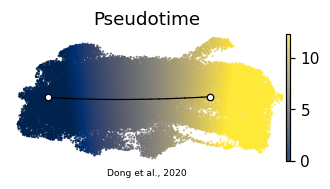

In [8]:
B = np.asarray(adata.uns['graph']['B']); F = adata.uns['graph']['F'].T
xy0 = adata.obsm['X_umap'].astype(float); cen = xy0.mean(0)
_,_,vt = np.linalg.svd(xy0-cen, full_matrices=False)
ang = np.arctan2(vt[0,1], vt[0,0]); cA,sA = np.cos(-ang), np.sin(-ang)
Rot = np.array([[cA,-sA],[sA,cA]])
Flin = (F-cen) @ Rot.T
if np.corrcoef(adata.obsm['X_umap_lin'][:,0], adata.obs['t'].values)[0,1] < 0:
    Flin = Flin @ np.array([[-1.,0.],[0.,-1.]]).T
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
tps = np.where((B>0).sum(0)==1)[0]
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=8, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ii,jj = np.where(np.triu(B>0))
for a,b in zip(ii,jj):
    ax.plot([Flin[a,0],Flin[b,0]],[Flin[a,1],Flin[b,1]], '-', color='k', lw=.8, zorder=5)
ax.scatter(Flin[tps,0], Flin[tps,1], c='w', s=18, edgecolor='k', lw=.8, zorder=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf (curve edges drawn)')